# Domi: seven NoSQL databases in one hour

In the lecture we talked about architectural thinking: start from the questions the system has to answer, then
pick the storage that answers them well. This lab is the other half. To choose between a hammer and a screwdriver
you have to have held both. Here you will use seven databases on the same data and notice, with your own hands,
what each one makes easy and what it makes painful.

**Domi** is a fictional food-delivery app in Bogotá. Each database holds one part of it, and most queries
come back to the same order:

> Friday 2026-10-30, 19:42. It's raining hard in Chapinero. Valentina orders from *El Ajiaco de la Abuela*:
> 1 Ajiaco santafereño + 1 Chocolate santafereño con queso + delivery = 46,900 COP.
> Jhon Fredy picks it up at 20:03 and delivers it at 20:21. That is order `O-000042`.

**How it works.** Each cell sends a native query (Redis commands, MongoDB shell, CQL, Cypher, SQL, JSON) to a
shared server. The helpers `redis("...")`, `mongo("...")`, etc. only carry your query there; they do not rewrite it.

- First do **File > Save a copy in Drive** so you can edit.
- **Your turn** sections are for you to write. **Where it breaks** sections show a question the database handles badly.
- Everyone shares the same data. Anything you write is tagged with your nickname so you can find it.

In [48]:
#@title Setup: fill in the three fields, then run this cell
GATEWAY = "http://20.124.81.3"  #@param {type:"string"}
CLASS_CODE = "domi"  #@param {type:"string"}
NICK = "mateo"  #@param {type:"string"}

%pip install -q requests pandas matplotlib fastembed

import json, re
import requests, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
pd.set_option("display.max_colwidth", 80)

NICK = re.sub(r"[^a-z0-9]", "", NICK.lower()) or "anon"
GATEWAY = GATEWAY.rstrip("/")


def _send(engine, query):
    r = requests.post(f"{GATEWAY}/{engine}", data=query.encode("utf-8"), timeout=20,
                      headers={"Authorization": f"Bearer {CLASS_CODE}"})
    if r.status_code != 200:
        try:
            msg = r.json().get("detail", r.text)
        except ValueError:
            msg = r.text
        print(f"Error {r.status_code}:", msg if isinstance(msg, str) else json.dumps(msg, ensure_ascii=False)[:500])
        return None
    return r.json()


def _table(x):
    """Show a list of rows as a table; anything else as-is."""
    if isinstance(x, list) and x and all(isinstance(r, dict) for r in x):
        return pd.DataFrame(x)
    return x


def redis(q):   return _send("redis", q)
def mongo(q):   return _table(_send("mongo", q))
def neo4j(q):   return _table(_send("neo4j", q))
def influx(q):  return _table(_send("influx", q))

def scylla(q):
    r = _send("scylla", q)
    if isinstance(r, dict) and "warnings" in r:
        for w in r["warnings"]:
            print("ScyllaDB warning:", w)
        r = r["rows"]
    return _table(r) if r != [] else "(no rows)"

def elastic(q):
    r = _send("elastic", q)
    if isinstance(r, dict) and "hits" in r:
        return pd.DataFrame([{"_score": round(h["_score"] or 0, 2), **h["_source"]} for h in r["hits"]["hits"]])
    return r

def qdrant(q):
    r = _send("qdrant", q)
    if isinstance(r, dict) and isinstance(r.get("result"), dict) and "points" in r["result"]:
        return pd.DataFrame([{"score": round(p["score"], 3), **p["payload"]} for p in r["result"]["points"]])
    return r


health = requests.get(f"{GATEWAY}/health", timeout=20).json()
print(f"Nickname: {NICK}")
print("Databases:", ", ".join(f"{e} {s}" for e, s in health.items()))
print("Class code accepted." if redis("PING") else "Class code rejected: check CLASS_CODE.")


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\david\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Nickname: mateo
Databases: redis up, mongo up, scylla up, neo4j up, influx up, elastic up, qdrant up
Class code accepted.


---
## 1. Key-value: Redis

Redis stores a value under a key. If you know the key, the read is instant. You cannot ask questions about the
values themselves. Domi uses it for sessions, carts, and the top-rated ranking.

Keys used here: `user:U-0001` (a hash with name and localidad) and `ranking:restaurants:rating` (a sorted set).

Get Valentina by her key.

In [49]:
redis("HGETALL user:U-0001")

{'name': 'Valentina Rojas', 'localidad': 'Chapinero'}

A login session that expires on its own after 30 seconds. Run the `TTL` cell a few times, then the `GET` cell.

In [50]:
redis(f"SET session:{NICK} U-0001 EX 30")

True

In [51]:
redis(f"TTL session:{NICK}")   # seconds left; run it again

30

In [52]:
redis(f"GET session:{NICK}")   # after 30 s this returns None: the key is gone

'U-0001'

Top 5 restaurants by rating. The sorted set stays ordered on every write, so reading the top is cheap.

In [53]:
redis("ZREVRANGE ranking:restaurants:rating 0 4 WITHSCORES")

['R-001',
 '4.8',
 'R-006',
 '4.7',
 'R-007',
 '4.6',
 'R-003',
 '4.6',
 'R-010',
 '4.5']

### Your turn
Build a cart: add 2 empanadas, then one more, then read the whole cart. Add another item too.

In [54]:
redis(f"HSET cart:{NICK} empanada 2")
redis(f"HINCRBY cart:{NICK} empanada 1")
redis(f"HGETALL cart:{NICK}")

{'empanada': '3'}

### Where it breaks
"Find all users who live in Suba." There is no command for that, because Redis only looks things up by key.
You would have needed to create a key like `localidad:suba:users` in advance. Also, on a shared server some
commands are disabled:

In [55]:
redis("DEL user:U-0001")

Error 403: DEL is disabled in this lab


---
## 2. Document: MongoDB

MongoDB stores each record as a document, shaped the way the application uses it: nested objects and arrays,
no fixed schema. Domi keeps orders with their items inside, and restaurants with their menus inside.

Order O-000042, whole. The items are inside the order, with the price as it was paid.

In [56]:
mongo('orders.findOne({_id: "O-000042"})')

{'_id': 'O-000042',
 'user_id': 'U-0001',
 'restaurant_id': 'R-001',
 'courier_id': 'C-01',
 'items': [{'dish_id': 'D-0001',
   'name': 'Ajiaco santafereño',
   'qty': 1,
   'unit_price_cop': 32000},
  {'dish_id': 'D-0002',
   'name': 'Chocolate santafereño con queso',
   'qty': 1,
   'unit_price_cop': 9000}],
 'delivery_fee_cop': 5900,
 'total_cop': 46900,
 'placed_at': '2026-10-31T00:42:00',
 'delivered_at': '2026-10-31T01:21:00'}

If El Ajiaco raises its prices tomorrow, Valentina's old order does not change. Embedding is a design decision.

Query inside an array: every order that contains an ajiaco.

In [57]:
mongo('orders.find({"items.name": "Ajiaco santafereño"}, {user_id: 1, total_cop: 1, placed_at: 1})')

,_id,user_id,total_cop,placed_at
0,O-000042,U-0001,46900,2026-10-31T00:42:00
1,O-000048,U-0016,87900,2026-10-20T02:07:10
2,O-000061,U-0007,81900,2026-10-20T17:43:22
3,O-000065,U-0037,70900,2026-10-20T21:04:05
4,O-000074,U-0006,114900,2026-10-20T23:29:46
5,O-000085,U-0059,52900,2026-10-21T02:17:21
6,O-000114,U-0034,87900,2026-10-22T01:10:29
7,O-000134,U-0035,63900,2026-10-22T19:48:45
8,O-000151,U-0044,56900,2026-10-23T13:06:20
9,O-000159,U-0059,110900,2026-10-23T21:27:53


MongoDB answers any question about the documents, but how much work does it do? `.explain()` shows the plan.
The full output is long, so the cell below keeps three fields: the strategy, the documents returned, and the
documents read to find them.

In [58]:
def plan(query):
    r = mongo(query)
    return {"stage": r["queryPlanner"]["winningPlan"]["stage"],
            "returned": r["executionStats"]["nReturned"],
            "documents read": r["executionStats"]["totalDocsExamined"]}

pd.DataFrame([plan('orders.find({_id: "O-000042"}).explain()'),
              plan('orders.find({user_id: "U-0001"}).explain()')],
             index=["by _id", "by user_id"])

,stage,returned,documents read
by _id,IDHACK,1,1
by user_id,COLLSCAN,10,479


`_id` always has an index (`IDHACK` is the shortcut for it). `user_id` has none, so MongoDB reads every order
(`COLLSCAN`). With 479 orders you can't tell the difference; with 50 million you can. A flexible schema doesn't
remove the need to design for your queries: you still choose which indexes to build.

Top 5 dishes: unwind the items, group by name, sort.

In [59]:
mongo('''orders.aggregate([
  {$unwind: "$items"},
  {$group: {_id: "$items.name", sold: {$sum: "$items.qty"}}},
  {$sort: {sold: -1}},
  {$limit: 5}
])''')

,_id,sold
0,Ajiaco santafereño,53
1,Tamal tolimense,50
2,Lechona,35
3,Crema de ahuyama,32
4,Caldo de costilla,30


### Your turn
Open your own restaurant, with a field no other restaurant has. MongoDB accepts it. Then find it.

In [60]:
mongo(f'restaurants.insertOne({{name: "Donde {NICK}", cuisine: "Fusion", author: "{NICK}", parking: true}})')
mongo(f'restaurants.find({{author: "{NICK}"}})')

,_id,name,cuisine,author,parking
0,6af7141694bd6ea719da6aa7,Donde mateo,Fusion,mateo,True


### Where it breaks
"Valentina's orders, with each restaurant's rating." The rating is in another collection, so you need `$lookup`,
which is a join. It works, but needing it often means the data was split the wrong way for this question.

In [61]:
mongo('''orders.aggregate([
  {$match: {user_id: "U-0001"}},
  {$lookup: {from: "restaurants", localField: "restaurant_id", foreignField: "_id", as: "restaurant"}},
  {$project: {total_cop: 1, rating: {$first: "$restaurant.rating"}}}
])''')

,_id,total_cop,rating
0,O-000011,32900,4.8
1,O-000042,46900,4.8
2,O-000206,57900,4.6
3,O-000271,21900,4.3
4,O-000275,11900,4.2
5,O-000423,68900,4.4
6,O-000426,17900,4.5
7,O-000430,49900,4.4
8,O-000463,38900,4.8
9,O-000479,69900,4.4


In [62]:
mongo('orders.deleteOne({_id: "O-000042"})')

Error 403: deleteOne is disabled in this lab


---
## 3. Wide-column: ScyllaDB (Cassandra's CQL)

ScyllaDB handles very high write volume and fast reads, but only when you query by the partition key. You design
one table per question, and storing the same data more than once is expected. CQL looks like SQL but does not
behave like it. Domi uses it for courier GPS pings and order history per user.

| Table | Partition key | Sorted by |
|---|---|---|
| `courier_pings_by_day` | `(courier_id, day)` | `ts DESC` |
| `orders_by_user` | `(user_id)` | `placed_at DESC` |

Jhon Fredy's GPS pings during order O-000042. Times are UTC: 20:03 in Bogotá is 01:03 UTC.

In [63]:
route = scylla("""SELECT ts, lat, lon FROM domi.courier_pings_by_day
WHERE courier_id = 'C-01' AND day = '2026-10-30'
  AND ts >= '2026-10-31 01:03:00+0000' AND ts <= '2026-10-31 01:21:00+0000'""")
route.head()

,ts,lat,lon
0,2026-10-31T01:21:00,4.653079,-74.058930
1,2026-10-31T01:20:30,4.652856,-74.059486
2,2026-10-31T01:20:00,4.653049,-74.060346
3,2026-10-31T01:19:30,4.652901,-74.061415
4,2026-10-31T01:19:00,4.652639,-74.062035


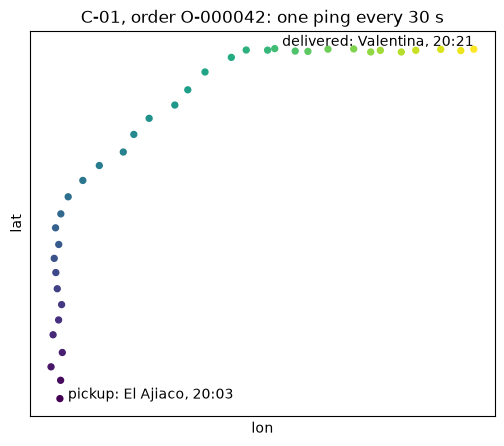

In [64]:
# the route: one partition, already sorted by time
plt.figure(figsize=(6, 5))
plt.scatter(route.lon, route.lat, c=range(len(route))[::-1], cmap="viridis", s=18)
plt.annotate("  pickup: El Ajiaco, 20:03", (route.lon.iloc[-1], route.lat.iloc[-1]))
plt.annotate("delivered: Valentina, 20:21", (route.lon.iloc[0], route.lat.iloc[0]), ha="right", va="bottom")
plt.xticks([]); plt.yticks([])
plt.title("C-01, order O-000042: one ping every 30 s"); plt.xlabel("lon"); plt.ylabel("lat"); plt.show()

Valentina's order history: one partition read, already sorted newest first.

In [65]:
scylla("SELECT * FROM domi.orders_by_user WHERE user_id = 'U-0001'")

,user_id,placed_at,order_id,restaurant_name,total_cop
0,U-0001,2026-11-01T04:51:25,O-000479,Tamales Doña Rosa,69900
1,U-0001,2026-11-01T00:57:40,O-000463,El Ajiaco de la Abuela,38900
2,U-0001,2026-10-31T06:38:07,O-000430,Smash 93,49900
3,U-0001,2026-10-31T02:55:20,O-000426,Arepas La 85,17900
4,U-0001,2026-10-31T02:48:33,O-000423,Tamales Doña Rosa,68900
5,U-0001,2026-10-31T00:42:00,O-000042,El Ajiaco de la Abuela,46900
6,U-0001,2026-10-27T19:43:25,O-000275,Pollo Brasa la 80,11900
7,U-0001,2026-10-27T17:16:53,O-000271,Fritanga El Rolo,21900
8,U-0001,2026-10-25T01:08:31,O-000206,Changua & Café,57900
9,U-0001,2026-10-18T18:50:21,O-000011,El Ajiaco de la Abuela,32900


Insert the same primary key twice with different totals. There is no error: the second write replaces the first.

In [66]:
scylla(f"INSERT INTO domi.orders_by_user (user_id, placed_at, order_id, restaurant_name, total_cop) VALUES ('S-{NICK}', '2026-11-13 20:00:00+0000', 'O-{NICK}', 'Test', 10000)")
scylla(f"INSERT INTO domi.orders_by_user (user_id, placed_at, order_id, restaurant_name, total_cop) VALUES ('S-{NICK}', '2026-11-13 20:00:00+0000', 'O-{NICK}', 'Test', 99999)")
scylla(f"SELECT * FROM domi.orders_by_user WHERE user_id = 'S-{NICK}'")

,user_id,placed_at,order_id,restaurant_name,total_cop
0,S-mateo,2026-11-13T20:00:00,O-mateo,Test,99999


### Your turn
You are a courier now. Insert a ping for `C-<you>` and read your partition back. Add a few more pings.

In [67]:
scylla(f"INSERT INTO domi.courier_pings_by_day (courier_id, day, ts, lat, lon) VALUES ('C-{NICK}', '2026-11-13', '2026-11-13 20:00:00+0000', 4.6486, -74.0628)")
scylla(f"SELECT * FROM domi.courier_pings_by_day WHERE courier_id = 'C-{NICK}' AND day = '2026-11-13'")

,courier_id,day,ts,lat,lon
0,C-mateo,2026-11-13,2026-11-13T20:00:00,4.6486,-74.0628


### Where it breaks
"All orders from El Ajiaco." Orders are partitioned by user, so ScyllaDB refuses to scan for a restaurant.
The fix is another table, `orders_by_restaurant`, with the same orders stored a second time.

In [68]:
scylla("SELECT * FROM domi.orders_by_user WHERE restaurant_name = 'El Ajiaco de la Abuela'")

Error 400: Error from server: code=2200 [Invalid query] message="Cannot execute this query as it might involve data filtering and thus may have unpredictable performance. If you want to execute this query despite the performance unpredictability, use ALLOW FILTERING"


---
## 4. Graph: Neo4j

Neo4j stores nodes and the relationships between them. A question that needs many JOINs in SQL becomes a single
pattern. Domi uses it for recommendations and the referral program.

`(User)-[:PLACED]->(Order)-[:CONTAINS]->(Dish)<-[:SERVES]-(Restaurant)`, `(Courier)-[:DELIVERED]->(Order)`, `(User)-[:REFERRED]->(User)`

Order O-000042 as a pattern. (Neo4j Browser can draw the same query as a picture.)

In [69]:
neo4j("""MATCH (u:User)-[:PLACED]->(o:Order {order_id: 'O-000042'})-[:CONTAINS]->(d:Dish)<-[:SERVES]-(r:Restaurant),
      (c:Courier)-[:DELIVERED]->(o)
RETURN u.name AS user, o.order_id AS order, d.name AS dish, r.name AS restaurant, c.name AS courier""")

,user,order,dish,restaurant,courier
0,Valentina Rojas,O-000042,Ajiaco santafereño,El Ajiaco de la Abuela,Jhon Fredy Ramírez
1,Valentina Rojas,O-000042,Chocolate santafereño con queso,El Ajiaco de la Abuela,Jhon Fredy Ramírez


Recommendations: what do other people who ordered ajiaco also order, that Valentina hasn't tried?

In [70]:
neo4j("""MATCH (v:User {user_id: 'U-0001'})-[:PLACED]->(:Order)-[:CONTAINS]->(a:Dish {name: 'Ajiaco santafereño'})
MATCH (a)<-[:CONTAINS]-(:Order)<-[:PLACED]-(other:User)-[:PLACED]->(:Order)-[:CONTAINS]->(rec:Dish)
WHERE other <> v AND NOT (v)-[:PLACED]->(:Order)-[:CONTAINS]->(rec)
RETURN rec.name AS dish, count(DISTINCT other) AS people
ORDER BY people DESC LIMIT 5""")

,dish,people
0,Limonada de coco,15
1,Crema de ahuyama,14
2,Lechona,11
3,Arepa de choclo,11
4,Arepa rellena de pollo,10


The referral chain: everyone Valentina brought in, up to 3 hops away.

In [71]:
neo4j("""MATCH path = (:User {user_id: 'U-0001'})-[:REFERRED*1..3]->(u:User)
RETURN u.name AS user, length(path) AS hops""")

,user,hops
0,Andrés Gómez,1
1,Camila Herrera,2
2,Santiago Martínez,3
3,david,3
4,yen,3


How is Valentina connected to Diego Cárdenas? The query doesn't say which relationships to follow: `[*]`
means any type, in any direction. Neo4j finds the shortest route on its own. In SQL you would have to know the
chain of joins in advance.

In [72]:
neo4j("""MATCH p = shortestPath((:User {user_id: 'U-0001'})-[*]-(:User {user_id: 'U-0005'}))
RETURN [n IN nodes(p) | coalesce(n.name, n.order_id)] AS path,
       [r IN relationships(p) | type(r)] AS relationships""")

,path,relationships
0,"[Valentina Rojas, O-000042, Chocolate santafereño con queso, O-000179, Diego...","[PLACED, CONTAINS, CONTAINS, PLACED]"


### Your turn
1. Join the referral chain: create yourself, have Camila refer you, then run the referral query above again. You should appear 3 hops from Valentina.
2. In the cell after that, change `[*]` to `[:REFERRED*]`, then to `[:PLACED|DELIVERED*]`. Which connections exist, and which don't?

In [73]:
neo4j(f"""MERGE (me:User {{user_id: 'S-{NICK}'}}) SET me.name = '{NICK}'
WITH me MATCH (camila:User {{user_id: 'U-0003'}})
MERGE (camila)-[:REFERRED]->(me)
RETURN camila.name AS referrer, me.name AS you""")

,referrer,you
0,Camila Herrera,mateo


In [74]:
neo4j("""MATCH p = shortestPath((:User {user_id: 'U-0001'})-[*]-(:User {user_id: 'U-0005'}))
RETURN [n IN nodes(p) | coalesce(n.name, n.order_id)] AS path""")

,path
0,"[Valentina Rojas, O-000042, Chocolate santafereño con queso, O-000179, Diego..."


### Where it breaks
This one is a contrast with SQL rather than a failure. The referral query above would be a recursive query in SQL
(`WITH RECURSIVE ... JOIN ... JOIN ...`); here it is one arrow with `*1..3`. Deleting on the shared graph is disabled:

In [75]:
neo4j("MATCH (u:User {user_id: 'U-0001'}) DETACH DELETE u")

Error 403: DELETE is disabled in this lab


---
## 5. Time-series: InfluxDB 3 (SQL)

InfluxDB stores measurements over time and is built for queries over time windows and aggregates. It uses SQL,
so what's new here is the model, not the language. Domi uses it for the operations dashboard, where one pattern
stands out: when it rains in Bogotá, orders go up.

| Table | Tags (filter and group by) | Fields (what is measured) |
|---|---|---|
| `orders` | `localidad`, `restaurant_id` | `total_cop` (one point per order) |
| `weather` | `localidad` | `rain_mm`, `temp_c` (hourly) |

Times are UTC. Bogotá is UTC-5.

Friday 2026-10-30 in Chapinero: orders per 15 minutes (`date_bin`), and the rain.

In [76]:
orders = influx("""SELECT date_bin(INTERVAL '15 minutes', time) AS t, count(*) AS orders
FROM orders
WHERE localidad = 'Chapinero' AND time >= '2026-10-30T11:00:00Z' AND time < '2026-10-31T05:00:00Z'
GROUP BY 1 ORDER BY 1""")
rain = influx("""SELECT time AS t, rain_mm FROM weather
WHERE localidad = 'Chapinero' AND time >= '2026-10-30T11:00:00Z' AND time < '2026-10-31T05:00:00Z'
ORDER BY time""")
orders.tail()

,t,orders
14,2026-10-31T01:45:00,1
15,2026-10-31T02:00:00,1
16,2026-10-31T02:15:00,1
17,2026-10-31T02:45:00,4
18,2026-10-31T03:15:00,1


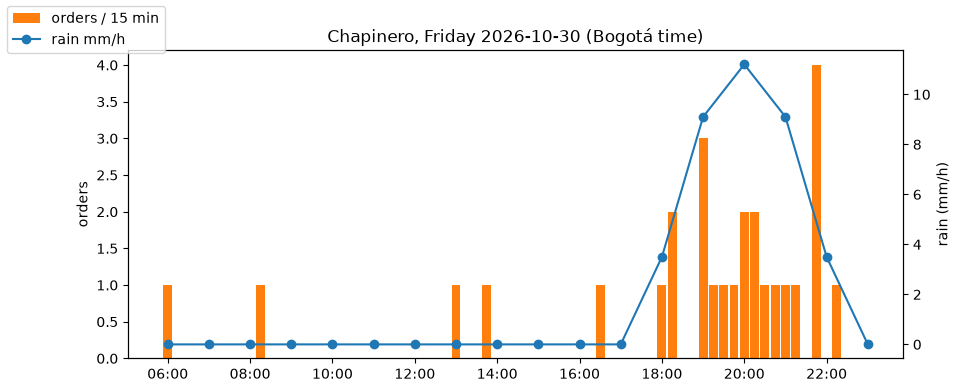

In [77]:
# orders vs. rain, in Bogotá time
bog = lambda s: pd.to_datetime(s) - pd.Timedelta(hours=5)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(bog(orders.t), orders.orders, width=0.009, color="tab:orange", label="orders / 15 min")
ax2 = ax.twinx()
ax2.plot(bog(rain.t), rain.rain_mm, color="tab:blue", marker="o", label="rain mm/h")
ax.set_ylabel("orders"); ax2.set_ylabel("rain (mm/h)")
ax.set_title("Chapinero, Friday 2026-10-30 (Bogotá time)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.legend(loc="upper left"); plt.show()

Orders by hour of day over two weeks (Bogotá time). Look for the lunch and dinner peaks.

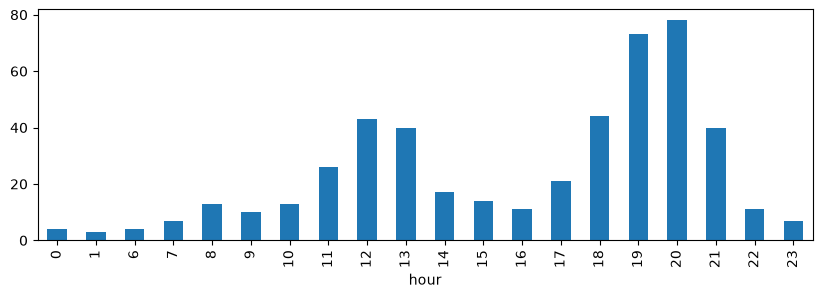

In [78]:
influx("""SELECT extract(hour FROM time - INTERVAL '5 hours') AS hour, count(*) AS orders
FROM orders GROUP BY 1 ORDER BY 1""").plot.bar(x="hour", y="orders", figsize=(10, 3), legend=False);

### Your turn
Report the weather where you are, in line protocol: `table,tag=...,tag=... field=...,field=...`. Then query it back.

In [79]:
influx(f"weather,localidad=Chapinero,author={NICK} rain_mm=12.5,temp_c=9.0")
influx(f"SELECT * FROM weather WHERE author = '{NICK}'")

,author,localidad,rain_mm,temp_c,time
0,mateo,Chapinero,12.5,9.0,2026-11-13T13:43:59.348883984


### Where it breaks
"Show me the items of order O-000042." They aren't here. There is no nested data and no lookup by ID.

In [80]:
influx("SELECT * FROM orders WHERE order_id = 'O-000042'")

Error 400: Schema error: No field named order_id. Did you mean 'orders.time'?.


---
## 6. Search: Elasticsearch

Elasticsearch does full-text search: it tolerates typos, accents and capitalization, and ranks the best match
first. Domi uses it for the search bar, over the `dishes` index. Each query has the form `METHOD /path` on the
first line, then the JSON body.

Typos still match. Try `ajiacco`, `AJIACO`, `santafereno`.

In [81]:
elastic("""GET /dishes/_search
{"query": {"multi_match": {"query": "ajiacco", "fields": ["name", "description"], "fuzziness": "AUTO"}},
 "_source": ["name", "restaurant_name"], "size": 5}""")

,_score,name,restaurant_name
0,3.07,Ajiaco santafereño,El Ajiaco de la Abuela


What the engine actually stores: tokens, lowercased, with the accents removed.

In [82]:
r = elastic("""GET /dishes/_analyze
{"text": "Ajiaco Santafereño con Guascas"}""")
[t["token"] for t in r["tokens"]]

['ajiaco', 'santafereno', 'con', 'guascas']

Text plus filters: soups in Chapinero for 30,000 COP or less.

In [83]:
elastic("""GET /dishes/_search
{"query": {"bool": {
   "must":   {"match": {"tags": "soup"}},
   "filter": [{"term": {"localidad": "Chapinero"}}, {"range": {"price_cop": {"lte": 30000}}}]}},
 "_source": ["name", "restaurant_name", "price_cop"]}""")

,_score,name,price_cop,restaurant_name
0,2.7,Crema de ahuyama,18000,Verde Bowl


### Your turn
Add your own dish to the menu, then find it with a typo.

In [84]:
MY_DISH = "Obleas con arequipe"   # change me
MY_TYPO = "obleas con arekipe"    # and this
elastic(f"""POST /dishes/_doc?refresh=true
{{"name": "{MY_DISH}", "description": "Made by {NICK}", "author": "{NICK}", "price_cop": 25000}}""")
elastic(f"""GET /dishes/_search
{{"query": {{"match": {{"name": {{"query": "{MY_TYPO}", "fuzziness": "AUTO"}}}}}}}}""")

,_score,name,description,author,price_cop,dish_id,tags,restaurant_name,localidad
0,5.52,Obleas con arequipe,Made by david,david,25000,NaN,NaN,NaN,NaN
1,5.52,Obleas con arequipe,Made by yen,yen,25000,NaN,NaN,NaN,NaN
2,5.52,Obleas con arequipe,Made by mateo,mateo,25000,NaN,NaN,NaN,NaN
3,1.61,Patacón con hogao,"Smashed fried green plantain topped with hogao, the tomato and onion sauce.",NaN,14000,D-0009,"[plantain, vegetarian, street food]",Arepas La 85,Chapinero
4,1.61,Café con leche,"Colombian coffee with steamed milk, the classic for breakfast.",NaN,6000,D-0035,"[drink, coffee]",Changua & Café,Teusaquillo
5,1.61,Arroz con pollo,"Yellow rice cooked with chicken, peas and carrots, with fries on the side.",NaN,19000,D-0042,"[chicken, rice]",Pollo Brasa la 80,Engativá
6,1.61,Maduro con queso,Sweet ripe plantain baked with melted cheese and bocadillo.,NaN,9000,D-0045,"[plantain, cheese]",Pollo Brasa la 80,Engativá
7,1.54,Milkshake de arequipe,"Vanilla ice cream blended with arequipe, Colombian dulce de leche.",NaN,14000,D-0025,"[drink, dessert]",Smash 93,Chapinero
8,1.38,Chocolate santafereño con queso,"Hot chocolate with fresh cheese melting in the cup. Cozy comfort on chilly, ...",NaN,9000,D-0002,"[drink, chocolate, colombian]",El Ajiaco de la Abuela,La Candelaria


### Where it breaks
"Something warm for a cold rainy night." The answer you'd expect is ajiaco, but no dish description contains
those words, so it doesn't come up near the top. We'll use the same phrase in the next section.

In [85]:
elastic("""GET /dishes/_search
{"query": {"multi_match": {"query": "something warm for a cold rainy night", "fields": ["name", "description", "tags"]}},
 "_source": ["name", "restaurant_name"], "size": 5}""")

,_score,name,restaurant_name
0,3.32,Café con leche,Changua & Café
1,3.07,Fritanga para dos,Fritanga El Rolo
2,2.68,Papas a la francesa,Pollo Brasa la 80
3,2.39,Falafel wrap,Verde Bowl
4,2.31,Gyoza,Koi Usaquén


---
## 7. Vector: Qdrant

Qdrant searches by meaning instead of by words. A model turns text into a list of numbers, and the database finds
the closest lists. Domi would use it for "I don't know what I want, something warm for a rainy night."

Every dish was turned into 384 numbers by the model `all-MiniLM-L6-v2`. You use the same model here for your query.

In [86]:
from fastembed import TextEmbedding
model = TextEmbedding("sentence-transformers/all-MiniLM-L6-v2")   # ~90 MB, first run takes a few seconds

def embed(text):
    return [round(float(x), 4) for x in next(model.embed([text]))]

What "ajiaco" looks like to the database.

In [87]:
v = embed("ajiaco")
print(len(v), "numbers:", v[:8], "...")

384 numbers: [-0.0538, 0.0252, -0.0556, 0.0207, -0.079, -0.0466, 0.0831, 0.032] ...


The phrase that failed in Elasticsearch, now searched by meaning.

In [88]:
v = embed("something warm for a cold rainy night")
qdrant(f"""POST /collections/dishes/points/query
{{"query": {json.dumps(v)}, "limit": 5, "with_payload": true}}""")

,score,dish_id,name,restaurant_name,localidad,price_cop,tags
0,0.350,D-0048,Crema de ahuyama,Verde Bowl,Chapinero,18000,"[soup, vegetarian]"
1,0.329,D-0002,Chocolate santafereño con queso,El Ajiaco de la Abuela,La Candelaria,9000,"[drink, chocolate, colombian]"
2,0.320,D-0031,Changua,Changua & Café,Teusaquillo,16000,"[soup, breakfast, egg]"
3,0.315,D-0001,Ajiaco santafereño,El Ajiaco de la Abuela,La Candelaria,32000,"[soup, colombian, chicken]"
4,0.309,D-0037,Caldo de costilla,Tamales Doña Rosa,Suba,15000,"[soup, beef, breakfast]"


Same search, restricted to Chapinero and under 30,000 COP (a payload filter).

In [89]:
qdrant(f"""POST /collections/dishes/points/query
{{"query": {json.dumps(v)}, "limit": 5, "with_payload": true,
  "filter": {{"must": [{{"key": "localidad", "match": {{"value": "Chapinero"}}}},
                      {{"key": "price_cop", "range": {{"lte": 30000}}}}]}}}}""")

,score,dish_id,name,restaurant_name,localidad,price_cop,tags
0,0.350,D-0048,Crema de ahuyama,Verde Bowl,Chapinero,18000,"[soup, vegetarian]"
1,0.282,D-0023,Chicken burger,Smash 93,Chapinero,27000,"[burger, chicken, fried]"
2,0.246,D-0010,Limonada de coco,Arepas La 85,Chapinero,9000,"[drink, coconut]"
3,0.208,D-0046,Quinoa bowl,Verde Bowl,Chapinero,27000,"[vegetarian, bowl, healthy]"
4,0.204,D-0008,Arepa rellena de pollo,Arepas La 85,Chapinero,15000,"[corn, chicken, street food]"


### Your turn
Search for your own craving: "something light after the gym", "a hangover breakfast", "algo para compartir".

In [90]:
CRAVING = "a hangover breakfast"   # change me
qdrant(f"""POST /collections/dishes/points/query
{{"query": {json.dumps(embed(CRAVING))}, "limit": 5, "with_payload": true}}""")

,score,dish_id,name,restaurant_name,localidad,price_cop,tags
0,0.448,D-0033,Huevos pericos,Changua & Café,Teusaquillo,13000,"[egg, breakfast]"
1,0.361,D-0048,Crema de ahuyama,Verde Bowl,Chapinero,18000,"[soup, vegetarian]"
2,0.350,D-0035,Café con leche,Changua & Café,Teusaquillo,6000,"[drink, coffee]"
3,0.347,D-0027,Lasagna,Pizzería La Macarena,Santa Fe,36000,"[pasta, beef, italian]"
4,0.345,D-0021,Smash burger,Smash 93,Chapinero,29000,"[burger, beef]"


### Where it breaks
Search for an exact code, `O-000042`. You still get 5 "nearest" dishes with scores that look meaningful, and they
mean nothing. Vectors are bad at exact matches, which is why real applications combine keyword and vector search.

In [91]:
qdrant(f"""POST /collections/dishes/points/query
{{"query": {json.dumps(embed("O-000042"))}, "limit": 5, "with_payload": true}}""")

,score,dish_id,name,restaurant_name,localidad,price_cop,tags
0,0.212,D-0018,Chorizo santarrosano,Fritanga El Rolo,Kennedy,15000,"[grill, pork]"
1,0.178,D-0043,Medio pollo,Pollo Brasa la 80,Engativá,24000,"[chicken, rotisserie]"
2,0.166,D-0015,Mochi de maracuyá,Koi Usaquén,Usaquén,12000,"[dessert, japanese]"
3,0.162,D-0042,Arroz con pollo,Pollo Brasa la 80,Engativá,19000,"[chicken, rice]"
4,0.160,D-0016,Fritanga para dos,Fritanga El Rolo,Kennedy,58000,"[grill, pork, sharing]"


---
## Wrap-up: which database answers which question?

| Domi question | Database | Why |
|---|---|---|
| Who is logged in? What's in my cart? | Redis (key-value) | You know the key and need the answer immediately |
| Show order O-000042 with its items | MongoDB (document) | One order is one document, read whole |
| Where was the courier every 30 s? My order history? | ScyllaDB (wide-column) | Many writes, read by partition key |
| Recommendations, referral chains | Neo4j (graph) | The relationships are the data |
| Do orders go up when it rains? | InfluxDB (time-series) | Aggregates over time windows |
| The search bar: "ajiacco" | Elasticsearch (search) | Text, typos, ranking |
| "Something warm for a rainy night" | Qdrant (vector) | Meaning, not words |

None of these is the best database. Each one is good at the questions it was designed for and awkward at the
rest, which is what the "Where it breaks" sections showed. Start from the question, then choose the tool.

---
## Exercise: choose the database

Domi wants to build the features below. For each one, choose a database and write one sentence on why. Then
name one you would *not* use, and why. Some have more than one reasonable answer, so be ready to defend yours.

1. Detect one credit card being used by many different accounts.
2. Surge pricing: count the orders per localidad over the last 5 minutes, all the time.
3. A restaurant's page, with its full menu, prices and photos.
4. Show the customer where their courier is right now.
5. Flag reviews that say almost the same thing in different words.
6. A "repeat my last order" button.

Last question: what would Domi lose if it ran everything on a single PostgreSQL database? What would it gain?

*Your answers:*

1.
2.
3.
4.
5.
6.